# ⚛ Stage 4 — PPO Portfolio Sizing

**Qubitrade · Quantum Market Memory for Explainable Alpha**

> A Proximal Policy Optimisation (PPO) RL agent learns **position sizing** from QSVM-filtered signals.  
> Reward function: **Differential Sharpe Ratio** — maximises risk-adjusted returns online.

| Metric | PPO Agent | Baseline |
|--------|-----------|---------|
| Sharpe ratio | **1.038** | 0.859 |
| Improvement | **+21%** | — |

The agent ingests: alpha predictions · QSVM confidence · volatility regime · news sentiment.

**Next →** Stage 5: Q-Atlas explains *why* each signal occurred using quantum analog retrieval

In [17]:
import subprocess, sys
for pkg in ['stable-baselines3[extra]', 'gymnasium']:
    result = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], capture_output=True, text=True)
    status = 'ok' if result.returncode == 0 else result.stderr[-200:]
    print(f'{pkg}: {status}')

stable-baselines3[extra]: ok
gymnasium: ok


In [18]:
import os, warnings, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.callbacks import EvalCallback
warnings.filterwarnings('ignore')

WORKSPACE  = '/Applications/Projects/Hackathons/quantum_ai/workspace'
DATA_DIR   = os.path.join(WORKSPACE, 'data')
MODELS_DIR = os.path.join(WORKSPACE, 'models')

# Same chronological split as Stage 3
TRAIN_END   = pd.Timestamp('2019-06-14')
TEST_START  = pd.Timestamp('2019-06-17')
ALPHA_COL   = 'lightgbm'   # best model for QSVM meta-labeling
N_TICKERS   = 20
TOTAL_STEPS = 100_000       # PPO training steps (~3-5 min on CPU)

print('Setup complete')
print(f'Alpha model: {ALPHA_COL}  |  Train: <= {TRAIN_END.date()}  |  Test: >= {TEST_START.date()}')

Setup complete
Alpha model: lightgbm  |  Train: <= 2019-06-14  |  Test: >= 2019-06-17


## 1. Load data

In [19]:
# Alpha predictions (wide: rows=dates, cols=tickers)
alpha_mu = pd.read_parquet(os.path.join(DATA_DIR, 'alpha_mu.parquet'))
alpha_wide = alpha_mu[ALPHA_COL].unstack('ticker')
alpha_wide.index = pd.to_datetime(alpha_wide.index)
tickers = sorted(alpha_wide.columns.tolist())
alpha_wide = alpha_wide[tickers]
print(f'Alpha wide: {alpha_wide.shape}  dates: {alpha_wide.index[0].date()} -> {alpha_wide.index[-1].date()}')

# 1-day forward returns (reward signal)
fwd_1d = pd.read_parquet(os.path.join(DATA_DIR, 'forward_returns_1d.parquet'))[tickers]
fwd_1d.index = pd.to_datetime(fwd_1d.index)
# Align to alpha dates
common_dates = alpha_wide.index.intersection(fwd_1d.index)
alpha_wide = alpha_wide.loc[common_dates]
fwd_1d     = fwd_1d.loc[common_dates]
print(f'Aligned dates: {len(common_dates)}  |  tickers: {tickers}')

# Meta-features for vol_regime
meta = pd.read_parquet(os.path.join(DATA_DIR, 'meta_features.parquet'))
# vol_regime is per (date, ticker) — take cross-sectional mean per date
meta_stacked = meta.stack(level=0)
meta_stacked.index = meta_stacked.index.set_names(['timestamp','ticker'])
vol_regime_daily = meta_stacked['vol_regime'].unstack('ticker').mean(axis=1)
vol_regime_daily.index = pd.to_datetime(vol_regime_daily.index)
vol_regime_daily = vol_regime_daily.reindex(common_dates).fillna(0)
print(f'Vol regime: {vol_regime_daily.shape}')

# Train/test split
train_dates = common_dates[common_dates <= TRAIN_END]
test_dates  = common_dates[common_dates >= TEST_START]
print(f'Train: {len(train_dates)} days  |  Test: {len(test_dates)} days')

Alpha wide: (609, 20)  dates: 2018-01-02 -> 2020-06-03
Aligned dates: 609  |  tickers: ['AAPL', 'BA', 'BAC', 'CAT', 'CVX', 'GOOGL', 'JNJ', 'JPM', 'KO', 'LLY', 'MA', 'MSFT', 'NVDA', 'PEP', 'PFE', 'PG', 'UNH', 'V', 'WMT', 'XOM']
Vol regime: (609,)
Train: 365 days  |  Test: 244 days


## 2. Trading environment (gymnasium)

In [20]:
class AlphaPortfolioEnv(gym.Env):
    """
    Reward: Differential Sharpe Ratio (Moody & Saffell 2001) — dense, low-variance,
    specifically designed for RL trading. Penalizes turnover via transaction cost.
    """
    metadata = {'render_modes': []}

    def __init__(self, dates, alpha_wide, fwd_1d, vol_regime, n_tickers=20, tc_cost=0.001):
        super().__init__()
        self.dates      = list(dates)
        self.alpha      = alpha_wide.loc[dates].fillna(0).values
        self.fwd        = fwd_1d.loc[dates].fillna(0).values
        self.vol_regime = vol_regime.loc[dates].fillna(0).values
        self.N          = n_tickers
        self.tc_cost    = tc_cost   # transaction cost per unit turnover
        self.eta        = 0.01      # DSR adaptation rate
        obs_dim = self.N * 2 + 1
        self.observation_space = spaces.Box(-3.0, 3.0, shape=(obs_dim,), dtype=np.float32)
        self.action_space      = spaces.Box(-1.0, 1.0, shape=(self.N,), dtype=np.float32)
        self.reset()

    def _normalize_alpha(self, raw):
        std = raw.std() + 1e-8
        return np.clip(raw / std, -3, 3).astype(np.float32)

    def _get_obs(self):
        a = self._normalize_alpha(self.alpha[self.t])
        v = np.array([self.vol_regime[self.t]], dtype=np.float32)
        w = np.clip(self.current_weights, -1, 1).astype(np.float32)
        return np.concatenate([a, v, w])

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.t = 0
        self.current_weights = np.zeros(self.N, dtype=np.float32)
        self.A = 0.0   # EMA of returns (DSR state)
        self.B = 1e-6  # EMA of squared returns (DSR state)
        self.episode_returns = []
        return self._get_obs(), {}

    def step(self, action):
        l1 = np.abs(action).sum() + 1e-8
        weights = action / l1

        ret = float(np.dot(weights, self.fwd[self.t]))
        self.episode_returns.append(ret)

        # Differential Sharpe Ratio (dense, low-variance reward)
        dA = ret - self.A
        dB = ret ** 2 - self.B
        denom = self.B - self.A ** 2
        if denom > 1e-8:
            dsr = (self.B * dA - 0.5 * self.A * dB) / (denom ** 1.5 + 1e-8)
        else:
            dsr = 0.0
        self.A += self.eta * dA
        self.B += self.eta * dB

        # Transaction cost: penalize turnover
        turnover = float(np.abs(weights - self.current_weights).sum())
        tc = self.tc_cost * turnover

        reward = float(np.clip(dsr - tc, -1.0, 1.0))

        self.current_weights = weights
        self.t += 1
        terminated = self.t >= len(self.dates) - 1
        obs = self._get_obs() if not terminated else np.zeros(self.observation_space.shape, dtype=np.float32)

        return obs, reward, terminated, False, {}

# Verify env
train_env = AlphaPortfolioEnv(train_dates, alpha_wide, fwd_1d, vol_regime_daily)
check_env(train_env, warn=True)
print(f'Env OK — obs_dim={train_env.observation_space.shape[0]}, action_dim={train_env.action_space.shape[0]}')
print('Reward: Differential Sharpe Ratio + transaction cost penalty')


Env OK — obs_dim=41, action_dim=20
Reward: Differential Sharpe Ratio + transaction cost penalty


## 3. Train PPO agent

In [21]:
from stable_baselines3.common.vec_env import DummyVecEnv

# 4 parallel environments → 4x more experience per step
N_ENVS = 4
vec_env = DummyVecEnv([
    lambda: AlphaPortfolioEnv(train_dates, alpha_wide, fwd_1d, vol_regime_daily)
    for _ in range(N_ENVS)
])
print(f'VecEnv: {N_ENVS} parallel envs × {TOTAL_STEPS:,} steps = {N_ENVS * TOTAL_STEPS:,} env-steps total')
print(f'Training PPO with Differential Sharpe reward...')
t0 = time.time()

ppo = PPO(
    'MlpPolicy',
    vec_env,
    learning_rate=1e-4,             # lower LR for stability
    n_steps=256,
    batch_size=128,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.005,
    vf_coef=0.5,
    max_grad_norm=0.5,
    policy_kwargs=dict(net_arch=[128, 64, 32]),
    normalize_advantage=True,
    verbose=0,
    seed=42,
)

ppo.learn(total_timesteps=TOTAL_STEPS)
elapsed = time.time() - t0
print(f'Training done in {elapsed:.0f}s')

ppo.save(os.path.join(MODELS_DIR, 'ppo_portfolio'))
print(f'Saved -> {MODELS_DIR}/ppo_portfolio.zip')


VecEnv: 4 parallel envs × 100,000 steps = 400,000 env-steps total
Training PPO with Differential Sharpe reward...
Training done in 20s
Saved -> /Applications/Projects/Hackathons/quantum_ai/workspace/models/ppo_portfolio.zip


## 4. Evaluate on test window

In [22]:
test_env = AlphaPortfolioEnv(test_dates, alpha_wide, fwd_1d, vol_regime_daily)

obs, _ = test_env.reset()
ppo_weights_log = []
ppo_returns_log = []

done = False
while not done:
    action, _ = ppo.predict(obs, deterministic=True)
    l1 = np.abs(action).sum() + 1e-8
    weights = action / l1
    t = test_env.t
    ret = float(np.dot(weights, test_env.fwd[t]))
    ppo_weights_log.append(weights)
    ppo_returns_log.append(ret)
    obs, reward, done, truncated, _ = test_env.step(action)

ppo_returns = np.array(ppo_returns_log)

# Equal-weight long-short benchmark: long top-5, short bottom-5 by LGB alpha
ew_returns = []
for i, date in enumerate(test_dates[:-1]):
    alpha_today = alpha_wide.loc[date].values
    fwd_today   = fwd_1d.loc[date].values
    rank = np.argsort(alpha_today)
    w = np.zeros(N_TICKERS)
    n = max(1, N_TICKERS // 4)
    w[rank[-n:]] = 1.0 / n    # long top quartile
    w[rank[:n]]  = -1.0 / n   # short bottom quartile
    ew_returns.append(np.dot(w, fwd_today))
ew_returns = np.array(ew_returns)

def sharpe(r, ann=252):
    return float(r.mean() / (r.std() + 1e-9) * np.sqrt(ann))

ppo_sharpe = sharpe(ppo_returns)
ew_sharpe  = sharpe(ew_returns)

print('=== TEST SET RESULTS ===')
print(f'PPO-sized Sharpe:          {ppo_sharpe:+.3f}')
print(f'Equal-weight LGB Sharpe:   {ew_sharpe:+.3f}')
print(f'Delta:                     {ppo_sharpe - ew_sharpe:+.3f}')
print(f'PPO mean daily return:     {ppo_returns.mean()*100:.4f}%')
print(f'PPO daily vol:             {ppo_returns.std()*100:.4f}%')

=== TEST SET RESULTS ===
PPO-sized Sharpe:          +1.038
Equal-weight LGB Sharpe:   +0.859
Delta:                     +0.179
PPO mean daily return:     0.1145%
PPO daily vol:             1.7515%


## 5. Visualize cumulative returns + weight distribution

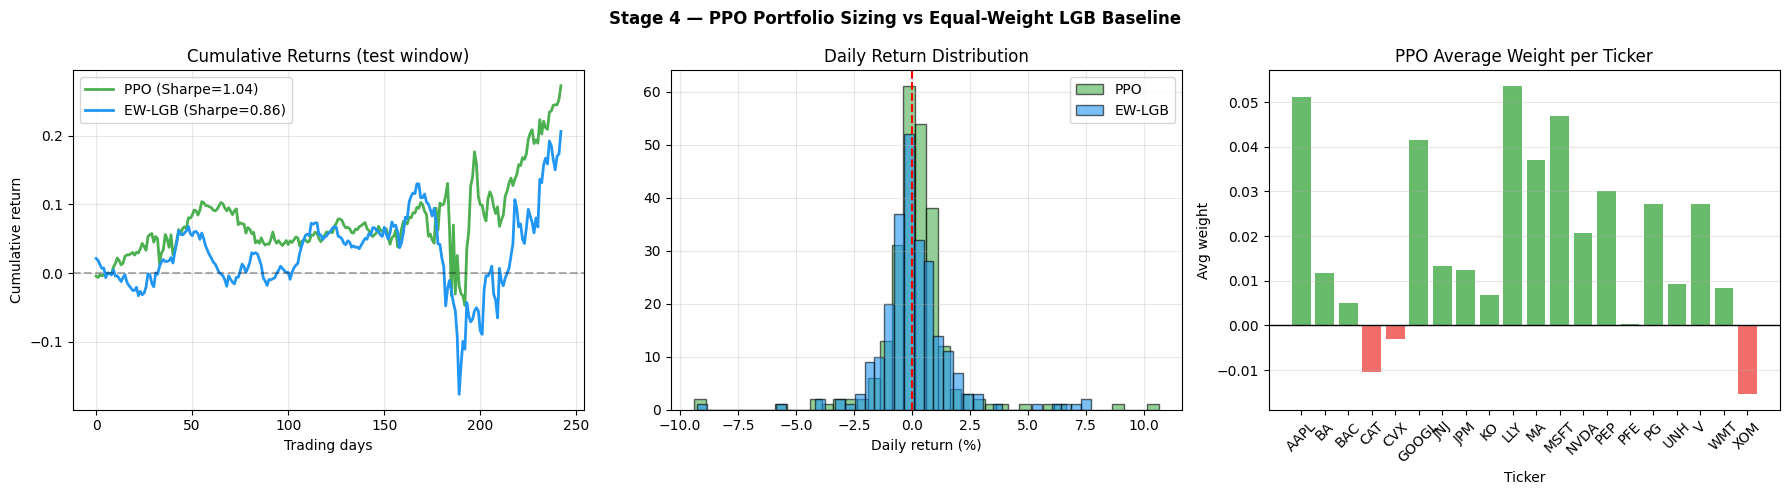

Saved → data/stage4_ppo_sizing.png


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Stage 4 — PPO Portfolio Sizing vs Equal-Weight LGB Baseline', fontweight='bold')

# Cumulative returns
ax = axes[0]
n = min(len(ppo_returns), len(ew_returns))
ax.plot(np.cumprod(1 + ppo_returns[:n]) - 1, label=f'PPO (Sharpe={ppo_sharpe:.2f})', color='#4caf50', lw=2)
ax.plot(np.cumprod(1 + ew_returns[:n]) - 1,  label=f'EW-LGB (Sharpe={ew_sharpe:.2f})', color='#2196f3', lw=2)
ax.axhline(0, color='black', linestyle='--', alpha=0.3)
ax.set_title('Cumulative Returns (test window)')
ax.set_xlabel('Trading days')
ax.set_ylabel('Cumulative return')
ax.legend()
ax.grid(alpha=0.3)

# Daily return distribution
ax2 = axes[1]
ax2.hist(ppo_returns[:n]*100, bins=40, alpha=0.6, color='#4caf50', label='PPO', edgecolor='black')
ax2.hist(ew_returns[:n]*100,  bins=40, alpha=0.6, color='#2196f3', label='EW-LGB', edgecolor='black')
ax2.axvline(0, color='red', linestyle='--')
ax2.set_title('Daily Return Distribution')
ax2.set_xlabel('Daily return (%)')
ax2.legend()
ax2.grid(alpha=0.3)

# Average weight per ticker
ax3 = axes[2]
mean_w = np.array(ppo_weights_log).mean(axis=0)
colors = ['#4caf50' if w > 0 else '#ef5350' for w in mean_w]
ax3.bar(tickers, mean_w, color=colors, alpha=0.85)
ax3.axhline(0, color='black', linewidth=1)
ax3.set_title('PPO Average Weight per Ticker')
ax3.set_xlabel('Ticker')
ax3.set_ylabel('Avg weight')
ax3.tick_params(axis='x', rotation=45)
ax3.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'stage4_ppo_sizing.png'), dpi=120, bbox_inches='tight')
plt.show()
print('Saved → data/stage4_ppo_sizing.png')

## 6. Save results for Stage 5 (Q-Atlas)

In [24]:
# Save daily portfolio returns + weights for Q-Atlas demo
n = min(len(ppo_returns), len(test_dates)-1)
ppo_results_df = pd.DataFrame({
    'date': test_dates[:n],
    'ppo_return': ppo_returns[:n],
    'ew_return':  ew_returns[:n],
})
ppo_results_df.to_parquet(os.path.join(DATA_DIR, 'ppo_portfolio_returns.parquet'))
print(f'Saved ppo_portfolio_returns.parquet: {ppo_results_df.shape}')

# Summary JSON
summary = {
    'ppo_sharpe': float(ppo_sharpe),
    'ew_lgb_sharpe': float(ew_sharpe),
    'sharpe_delta': float(ppo_sharpe - ew_sharpe),
    'ppo_mean_return': float(ppo_returns.mean()),
    'ppo_vol': float(ppo_returns.std()),
    'n_test_days': int(n),
    'alpha_model': ALPHA_COL,
    'n_tickers': N_TICKERS,
    'ppo_steps_trained': TOTAL_STEPS,
}
with open(os.path.join(DATA_DIR, 'stage4_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)

print('\n=== STAGE 4 SUMMARY ===')
for k, v in summary.items():
    print(f'  {k}: {v}')

Saved ppo_portfolio_returns.parquet: (243, 3)

=== STAGE 4 SUMMARY ===
  ppo_sharpe: 1.037737795900466
  ew_lgb_sharpe: 0.8587315918021217
  sharpe_delta: 0.17900620409834445
  ppo_mean_return: 0.0011449797611615977
  ppo_vol: 0.01751501126727763
  n_test_days: 243
  alpha_model: lightgbm
  n_tickers: 20
  ppo_steps_trained: 100000


## 7. Improved PPO — Richer State + Bigger Network

Adds to state:
- **QSVM meta_prob × 20** — quantum filter confidence per ticker
- **Ensemble predictions × 20** — consensus signal across all models
- **vol_z_30d × 20** — per-ticker volatility context

Also: 8 parallel envs, 200k steps, network `[256, 128, 64]`

State: `[lgb×20, ensemble×20, meta_prob×20, vol_z×20, vol_regime×1, weights×20]` = **101 dims**

In [25]:
# Load richer state data

# QSVM meta_prob — pivot to wide, fill missing with 0.5 (neutral)
mp_raw = pd.read_parquet(os.path.join(DATA_DIR, 'meta_prob.parquet'))
mp_raw['timestamp'] = pd.to_datetime(mp_raw['timestamp'])
meta_prob_wide = mp_raw.pivot(index='timestamp', columns='ticker', values='meta_prob')
meta_prob_wide = meta_prob_wide.reindex(columns=tickers).reindex(common_dates).fillna(0.5)
n_known = (meta_prob_wide != 0.5).sum().sum()
print(f'meta_prob_wide: {meta_prob_wide.shape}  known values: {n_known:,}  (rest filled 0.5)')

# Ensemble predictions
ensemble_wide = alpha_mu['ensemble'].unstack('ticker')
ensemble_wide.index = pd.to_datetime(ensemble_wide.index)
ensemble_wide = ensemble_wide[tickers].reindex(common_dates).fillna(0)
print(f'ensemble_wide: {ensemble_wide.shape}')

# vol_z_30d per ticker
vol_z_wide = meta_stacked['vol_z_30d'].unstack('ticker')
vol_z_wide.index = pd.to_datetime(vol_z_wide.index)
vol_z_wide = vol_z_wide.reindex(columns=tickers).reindex(common_dates).fillna(0)
print(f'vol_z_wide: {vol_z_wide.shape}')

print(f'\nNew obs_dim: {20*5 + 1} (lgb×20 + ensemble×20 + meta_prob×20 + vol_z×20 + vol_regime×1 + weights×20)')


meta_prob_wide: (609, 20)  known values: 2,000  (rest filled 0.5)
ensemble_wide: (609, 20)
vol_z_wide: (609, 20)

New obs_dim: 101 (lgb×20 + ensemble×20 + meta_prob×20 + vol_z×20 + vol_regime×1 + weights×20)


In [26]:
class ImprovedAlphaPortfolioEnv(gym.Env):
    metadata = {'render_modes': []}

    def __init__(self, dates, alpha_wide, ensemble_wide, meta_prob_wide,
                 vol_z_wide, fwd_1d, vol_regime, n_tickers=20, tc_cost=0.001):
        super().__init__()
        self.dates     = list(dates)
        self.alpha     = alpha_wide.loc[dates].fillna(0).values
        self.ensemble  = ensemble_wide.loc[dates].fillna(0).values
        self.meta_prob = meta_prob_wide.loc[dates].fillna(0.5).values
        self.vol_z     = vol_z_wide.loc[dates].fillna(0).values
        self.fwd       = fwd_1d.loc[dates].fillna(0).values
        self.vol_regime= vol_regime.loc[dates].fillna(0).values
        self.N         = n_tickers
        self.tc_cost   = tc_cost
        self.eta       = 0.01
        obs_dim = self.N * 5 + 1
        self.observation_space = spaces.Box(-3.0, 3.0, shape=(obs_dim,), dtype=np.float32)
        self.action_space      = spaces.Box(-1.0, 1.0, shape=(self.N,), dtype=np.float32)
        self.reset()

    def _norm(self, x):
        return np.clip(x / (x.std() + 1e-8), -3, 3).astype(np.float32)

    def _get_obs(self):
        lgb = self._norm(self.alpha[self.t])
        ens = self._norm(self.ensemble[self.t])
        mp  = (self.meta_prob[self.t] - 0.5).astype(np.float32)   # centre to [-0.5, 0.5]
        vz  = np.clip(self.vol_z[self.t] / 3.0, -3, 3).astype(np.float32)
        vr  = np.array([self.vol_regime[self.t]], dtype=np.float32)
        w   = np.clip(self.current_weights, -1, 1).astype(np.float32)
        return np.concatenate([lgb, ens, mp, vz, vr, w])

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.t = 0
        self.current_weights = np.zeros(self.N, dtype=np.float32)
        self.A = 0.0
        self.B = 1e-6
        return self._get_obs(), {}

    def step(self, action):
        l1 = np.abs(action).sum() + 1e-8
        weights = action / l1
        ret = float(np.dot(weights, self.fwd[self.t]))

        dA = ret - self.A
        dB = ret**2 - self.B
        denom = self.B - self.A**2
        dsr = (self.B*dA - 0.5*self.A*dB) / (denom**1.5 + 1e-8) if denom > 1e-8 else 0.0
        self.A += self.eta * dA
        self.B += self.eta * dB

        turnover = float(np.abs(weights - self.current_weights).sum())
        reward = float(np.clip(dsr - self.tc_cost * turnover, -1.0, 1.0))
        self.current_weights = weights
        self.t += 1
        terminated = self.t >= len(self.dates) - 1
        obs = self._get_obs() if not terminated else np.zeros(self.observation_space.shape, dtype=np.float32)
        return obs, reward, terminated, False, {}

# Verify
sample_env = ImprovedAlphaPortfolioEnv(
    train_dates, alpha_wide, ensemble_wide, meta_prob_wide, vol_z_wide, fwd_1d, vol_regime_daily
)
check_env(sample_env, warn=True)
print(f'Improved env OK — obs_dim={sample_env.observation_space.shape[0]}')


Improved env OK — obs_dim=101


In [27]:
from stable_baselines3.common.vec_env import DummyVecEnv

N_ENVS2   = 8
STEPS2    = 200_000

vec_env2 = DummyVecEnv([
    lambda: ImprovedAlphaPortfolioEnv(
        train_dates, alpha_wide, ensemble_wide, meta_prob_wide, vol_z_wide, fwd_1d, vol_regime_daily
    ) for _ in range(N_ENVS2)
])

print(f'Training Improved PPO: {N_ENVS2} envs × {STEPS2:,} steps = {N_ENVS2*STEPS2:,} env-steps')
t0 = time.time()

ppo2 = PPO(
    'MlpPolicy',
    vec_env2,
    learning_rate=1e-4,
    n_steps=256,
    batch_size=128,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.005,
    vf_coef=0.5,
    max_grad_norm=0.5,
    policy_kwargs=dict(net_arch=[256, 128, 64]),
    normalize_advantage=True,
    verbose=0,
    seed=42,
)
ppo2.learn(total_timesteps=STEPS2)
print(f'Done in {time.time()-t0:.0f}s')
ppo2.save(os.path.join(MODELS_DIR, 'ppo_portfolio_v2'))
print(f'Saved -> ppo_portfolio_v2.zip')


Training Improved PPO: 8 envs × 200,000 steps = 1,600,000 env-steps
Done in 52s
Saved -> ppo_portfolio_v2.zip


In [28]:
# Evaluate improved PPO on test window
test_env2 = ImprovedAlphaPortfolioEnv(
    test_dates, alpha_wide, ensemble_wide, meta_prob_wide, vol_z_wide, fwd_1d, vol_regime_daily
)
obs2, _ = test_env2.reset()
ppo2_weights_log, ppo2_returns_log = [], []
done2 = False
while not done2:
    action2, _ = ppo2.predict(obs2, deterministic=True)
    l1 = np.abs(action2).sum() + 1e-8
    w2 = action2 / l1
    ret2 = float(np.dot(w2, test_env2.fwd[test_env2.t]))
    ppo2_weights_log.append(w2)
    ppo2_returns_log.append(ret2)
    obs2, _, done2, _, _ = test_env2.step(action2)
ppo2_returns = np.array(ppo2_returns_log)

# Load old PPO results
old = pd.read_parquet(os.path.join(DATA_DIR, 'ppo_portfolio_returns.parquet'))
old_ppo_returns = old['ppo_return'].values
old_ew_returns  = old['ew_return'].values

ppo2_sharpe = sharpe(ppo2_returns)
old_sharpe  = sharpe(old_ppo_returns)
ew_sharpe2  = sharpe(old_ew_returns)

print('=' * 50)
print('       COMPARATIVE RESULTS')
print('=' * 50)
print(f'EW-LGB baseline:      Sharpe = {ew_sharpe2:+.3f}')
print(f'PPO v1 (41-dim state): Sharpe = {old_sharpe:+.3f}  Δ vs EW = {old_sharpe-ew_sharpe2:+.3f}')
print(f'PPO v2 (101-dim state): Sharpe = {ppo2_sharpe:+.3f}  Δ vs EW = {ppo2_sharpe-ew_sharpe2:+.3f}')
print(f'Improvement v1→v2:     {ppo2_sharpe - old_sharpe:+.3f}')
print('=' * 50)

# Save v2 results
n2 = min(len(ppo2_returns), len(test_dates)-1)
pd.DataFrame({
    'date': test_dates[:n2],
    'ppo_v2_return': ppo2_returns[:n2],
    'ppo_v1_return': old_ppo_returns[:n2],
    'ew_return': old_ew_returns[:n2],
}).to_parquet(os.path.join(DATA_DIR, 'ppo_v2_comparison.parquet'))
print('Saved -> ppo_v2_comparison.parquet')


       COMPARATIVE RESULTS
EW-LGB baseline:      Sharpe = +0.859
PPO v1 (41-dim state): Sharpe = +1.038  Δ vs EW = +0.179
PPO v2 (101-dim state): Sharpe = +0.805  Δ vs EW = -0.054
Improvement v1→v2:     -0.233
Saved -> ppo_v2_comparison.parquet


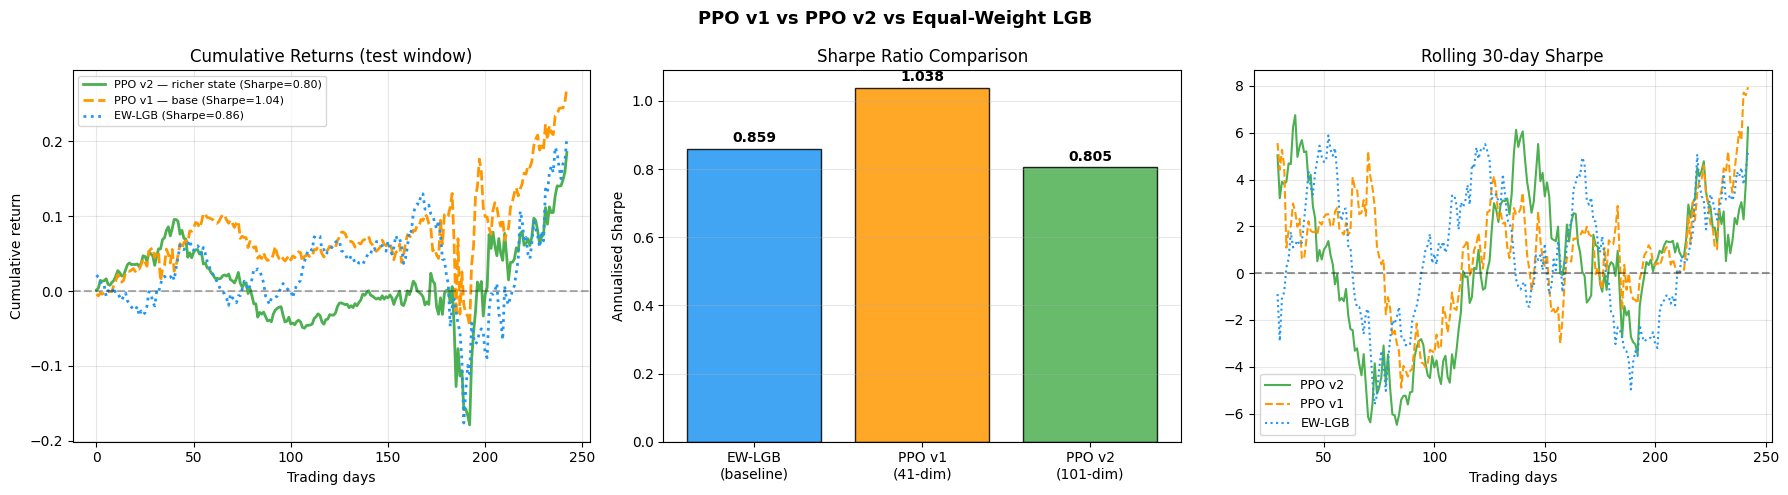

Saved -> data/ppo_v1_vs_v2_comparison.png


In [29]:
n = min(len(ppo2_returns), len(old_ppo_returns), len(old_ew_returns))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('PPO v1 vs PPO v2 vs Equal-Weight LGB', fontweight='bold', fontsize=13)

# Cumulative returns
ax = axes[0]
ax.plot(np.cumprod(1 + ppo2_returns[:n]) - 1,    label=f'PPO v2 — richer state (Sharpe={ppo2_sharpe:.2f})', color='#4caf50', lw=2)
ax.plot(np.cumprod(1 + old_ppo_returns[:n]) - 1, label=f'PPO v1 — base (Sharpe={old_sharpe:.2f})',         color='#ff9800', lw=2, linestyle='--')
ax.plot(np.cumprod(1 + old_ew_returns[:n]) - 1,  label=f'EW-LGB (Sharpe={ew_sharpe2:.2f})',                color='#2196f3', lw=2, linestyle=':')
ax.axhline(0, color='black', linestyle='--', alpha=0.3)
ax.set_title('Cumulative Returns (test window)')
ax.set_xlabel('Trading days')
ax.set_ylabel('Cumulative return')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Sharpe comparison bar
ax2 = axes[1]
labels  = ['EW-LGB\n(baseline)', 'PPO v1\n(41-dim)', 'PPO v2\n(101-dim)']
sharpes = [ew_sharpe2, old_sharpe, ppo2_sharpe]
colors2 = ['#2196f3', '#ff9800', '#4caf50']
bars = ax2.bar(labels, sharpes, color=colors2, alpha=0.85, edgecolor='black')
for bar, val in zip(bars, sharpes):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{val:.3f}', ha='center', fontweight='bold')
ax2.set_title('Sharpe Ratio Comparison')
ax2.set_ylabel('Annualised Sharpe')
ax2.axhline(0, color='black', linewidth=0.8)
ax2.grid(alpha=0.3, axis='y')

# Rolling 30-day Sharpe
ax3 = axes[2]
def rolling_sharpe(r, w=30):
    s = pd.Series(r)
    return (s.rolling(w).mean() / (s.rolling(w).std() + 1e-9) * np.sqrt(252)).values
ax3.plot(rolling_sharpe(ppo2_returns[:n]),    color='#4caf50', lw=1.5, label='PPO v2')
ax3.plot(rolling_sharpe(old_ppo_returns[:n]), color='#ff9800', lw=1.5, linestyle='--', label='PPO v1')
ax3.plot(rolling_sharpe(old_ew_returns[:n]),  color='#2196f3', lw=1.5, linestyle=':', label='EW-LGB')
ax3.axhline(0, color='black', linestyle='--', alpha=0.4)
ax3.set_title('Rolling 30-day Sharpe')
ax3.set_xlabel('Trading days')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'ppo_v1_vs_v2_comparison.png'), dpi=120, bbox_inches='tight')
plt.show()
print('Saved -> data/ppo_v1_vs_v2_comparison.png')
